In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial import cKDTree

MODE = "full"
N_REGIONS = 40

assert MODE in ["test", "full"]

folder = "results/jackknife_" + MODE
os.makedirs(folder, exist_ok=True)

columns = ["ra", "dec", "z", "weight"]

galaxy = pd.read_csv(
    "processed/boss_cmass_north_galaxy.csv.gz",
    usecols=columns,
)
random = pd.read_csv(
    "processed/boss_cmass_north_random.csv.gz",
    usecols=columns,
)

joint = pd.read_csv("../comparison/results/joint_summary.csv")
OMEGA_M = joint.loc[0, "Omega_m"]

edges = np.arange(20.0, 165.0, 5.0)
s = (edges[:-1] + edges[1:]) / 2

In [2]:
def directions(df):
    ra = df["ra"].values * np.pi / 180
    dec = df["dec"].values * np.pi / 180

    return np.column_stack((
        np.cos(dec) * np.cos(ra),
        np.cos(dec) * np.sin(ra),
        np.sin(dec),
    ))


center_file = "processed/boss_jk_centers.csv"

if not os.path.isfile(center_file):
    reference = random.sample(
        n=min(50000, len(random)),
        random_state=42,
    )

    model = KMeans(
        n_clusters=N_REGIONS,
        n_init=10,
        random_state=42,
    )
    model.fit(directions(reference))

    pd.DataFrame(
        model.cluster_centers_,
        columns=["x", "y", "z"],
    ).to_csv(center_file, index=False)

centers = pd.read_csv(
    center_file,
    float_precision="round_trip",
).values

assert centers.shape == (N_REGIONS, 3)
assert np.isfinite(centers).all()

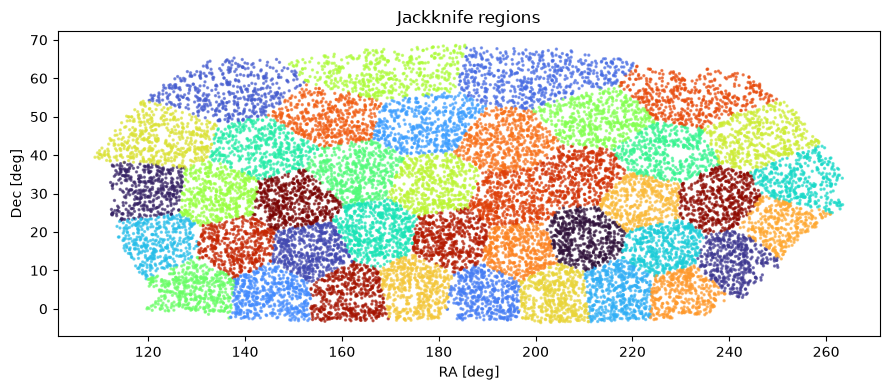

In [3]:
if MODE == "test":
    galaxy = galaxy.sample(
        n=min(20000, len(galaxy)),
        random_state=42,
    ).copy()

    random = random.sample(
        n=min(100000, len(random)),
        random_state=43,
    ).copy()

    regions = list(range(3))
else:
    regions = list(range(N_REGIONS))

direction_g = directions(galaxy)
direction_r = directions(random)

center_tree = cKDTree(centers)
region_g = center_tree.query(direction_g)[1]
region_r = center_tree.query(direction_r)[1]

region_counts = pd.DataFrame({
    "region": np.arange(N_REGIONS),
    "galaxies": np.bincount(region_g, minlength=N_REGIONS),
    "randoms": np.bincount(region_r, minlength=N_REGIONS),
})

assert (region_counts["galaxies"] > 0).all()
assert (region_counts["randoms"] > 0).all()

plt.figure(figsize=(9, 4))
plt.scatter(
    galaxy["ra"],
    galaxy["dec"],
    c=region_g,
    cmap="turbo",
    s=2,
    alpha=0.6,
)
plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")
plt.title("Jackknife regions")
plt.tight_layout()
plt.show()

In [4]:
z_grid = np.linspace(0, 0.70, 10001)
dz = z_grid[1] - z_grid[0]

inv_e = 1 / (
    OMEGA_M * (1 + z_grid)**3 + 1 - OMEGA_M
)**0.5

integral = np.zeros(len(z_grid))
integral[1:] = np.cumsum(
    (inv_e[:-1] + inv_e[1:]) * dz / 2
)

distance_g = 2997.92458 * np.interp(
    galaxy["z"].values, z_grid, integral
)
distance_r = 2997.92458 * np.interp(
    random["z"].values, z_grid, integral
)

xyz_g = direction_g * distance_g.reshape(-1, 1)
xyz_r = direction_r * distance_r.reshape(-1, 1)

wg = np.array(galaxy["weight"], dtype=float, copy=True)
wr = np.array(random["weight"], dtype=float, copy=True)

region_counts.to_csv(folder + "/region_counts.csv", index=False)

In [5]:
def correlation_without(region):
    keep_g = region_g != region
    keep_r = region_r != region

    xg = xyz_g[keep_g]
    xr = xyz_r[keep_r]
    w_g = wg[keep_g].copy()
    w_r = wr[keep_r].copy()

    tree_g = cKDTree(xg)
    tree_r = cKDTree(xr)

    dd = tree_g.count_neighbors(
        tree_g, edges,
        weights=(w_g, w_g),
        cumulative=False,
    )[1:]

    dr = tree_g.count_neighbors(
        tree_r, edges,
        weights=(w_g, w_r),
        cumulative=False,
    )[1:]

    rr = tree_r.count_neighbors(
        tree_r, edges,
        weights=(w_r, w_r),
        cumulative=False,
    )[1:]

    dd = dd / (np.sum(w_g)**2 - np.sum(w_g**2))
    dr = dr / (np.sum(w_g) * np.sum(w_r))
    rr = rr / (np.sum(w_r)**2 - np.sum(w_r**2))

    assert (rr > 0).all()

    return pd.DataFrame({
        "s": s,
        "DD": dd,
        "DR": dr,
        "RR": rr,
        "xi": (dd - 2 * dr + rr) / rr,
    })

In [7]:
records = []

for region in regions:
    filename = folder + "/region_" + str(region) + ".csv"

    if os.path.isfile(filename):
        saved = pd.read_csv(filename)
        status = "existing"
    else:
        saved = correlation_without(region)
        saved["excluded_region"] = region

        saved.to_csv(filename + ".part", index=False)
        os.replace(filename + ".part", filename)
        status = "saved"

    assert len(saved) == len(s)
    assert np.allclose(saved["s"], s)
    assert np.isfinite(saved["xi"]).all()

    records.append({
        "excluded_region": region,
        "status": status,
    })

pd.DataFrame(records)

,excluded_region,status
0,0,saved
1,1,saved
2,2,saved


In [9]:
baseline_file = folder + "/baseline.csv"

if MODE == "full":
    settings = pd.read_csv("results/boss_correlation_settings.csv")
    baseline = pd.read_csv("results/boss_correlation.csv")

    assert np.isclose(settings.loc[0, "Omega_m"], OMEGA_M)
    assert settings.loc[0, "galaxies"] == len(galaxy)
    assert settings.loc[0, "randoms"] == len(random)

    assert np.isclose(
        settings.loc[0, "sum_weight_galaxy"], np.sum(wg)
    )
    assert np.isclose(
        settings.loc[0, "sum_weight_random"], np.sum(wr)
    )
    assert np.allclose(baseline["s_low"], edges[:-1])
    assert np.allclose(baseline["s_high"], edges[1:])

    baseline = baseline[["s", "xi"]].copy()

elif os.path.isfile(baseline_file):
    baseline = pd.read_csv(baseline_file)

else:
    baseline = correlation_without(-1)[["s", "xi"]]

assert np.allclose(baseline["s"], s)
assert np.isfinite(baseline["xi"]).all()

baseline.to_csv(baseline_file + ".part", index=False)
os.replace(baseline_file + ".part", baseline_file)

In [10]:
records = []

for region in regions:
    filename = folder + "/region_" + str(region) + ".csv"

    if os.path.isfile(filename):
        saved = pd.read_csv(filename)
        status = "existing"
    else:
        saved = correlation_without(region)
        saved["excluded_region"] = region

        saved.to_csv(filename + ".part", index=False)
        os.replace(filename + ".part", filename)
        status = "saved"

    assert len(saved) == len(s)
    assert np.allclose(saved["s"], s)
    assert np.isfinite(saved["xi"]).all()
    assert (saved["excluded_region"] == region).all()

    records.append({
        "excluded_region": region,
        "status": status,
    })

    pd.DataFrame(records).to_csv(
        folder + "/progress.csv",
        index=False,
    )

pd.DataFrame(records)

,excluded_region,status
0,0,existing
1,1,existing
2,2,existing


In [11]:
curves = []

for region in regions:
    saved = pd.read_csv(
        folder + "/region_" + str(region) + ".csv"
    )

    assert np.allclose(saved["s"], s)
    assert np.isfinite(saved["xi"]).all()

    curves.append(saved["xi"].values)

curves = np.array(curves)

pd.DataFrame(
    curves,
    index=regions,
    columns=s,
).to_csv(folder + "/jackknife_curves.csv", index_label="excluded_region")

if MODE == "full":
    assert len(curves) == N_REGIONS

    mean_xi = np.mean(curves, axis=0)
    difference = curves - mean_xi

    covariance = (
        (N_REGIONS - 1) / N_REGIONS
        * (difference.T @ difference)
    )

    sigma = np.diag(covariance)**0.5

    assert np.isfinite(covariance).all()
    assert (sigma > 0).all()

    correlation_matrix = covariance / np.outer(sigma, sigma)

    pd.DataFrame(
        covariance,
        index=s,
        columns=s,
    ).to_csv(folder + "/covariance.csv", index_label="s")

    pd.DataFrame(
        correlation_matrix,
        index=s,
        columns=s,
    ).to_csv(folder + "/correlation_matrix.csv", index_label="s")

    measurement = pd.DataFrame({
        "s": s,
        "xi": baseline["xi"].values,
        "sigma_xi": sigma,
        "s2_xi": s**2 * baseline["xi"].values,
        "sigma_s2_xi": s**2 * sigma,
        "jackknife_mean_xi": mean_xi,
    })

    measurement.to_csv(folder + "/measurement.csv", index=False)

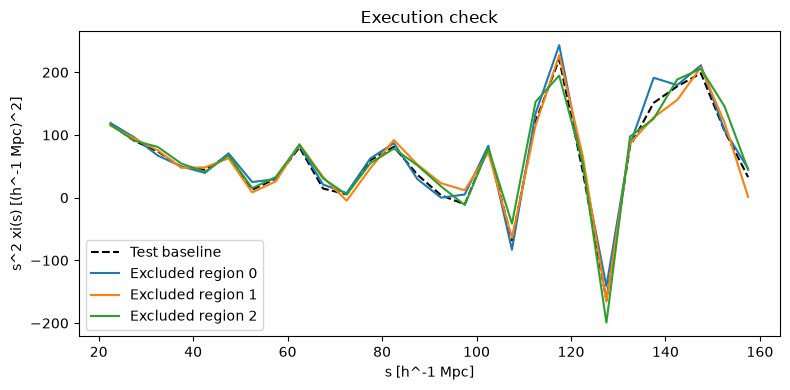

In [12]:
if MODE == "test":
    plt.figure(figsize=(8, 4))

    plt.plot(
        s,
        s**2 * baseline["xi"].values,
        "k--",
        label="Test baseline",
    )

    for i, region in enumerate(regions):
        plt.plot(
            s,
            s**2 * curves[i],
            label="Excluded region " + str(region),
        )

    plt.xlabel("s [h^-1 Mpc]")
    plt.ylabel("s^2 xi(s) [(h^-1 Mpc)^2]")
    plt.title("Execution check")
    plt.legend()
    plt.tight_layout()
    plt.savefig(folder + "/test_curves.png", dpi=200)
    plt.show()

else:
    measurement = pd.read_csv(folder + "/measurement.csv")

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.errorbar(
        measurement["s"],
        measurement["xi"],
        yerr=measurement["sigma_xi"],
        fmt="o-",
        capsize=3,
    )
    plt.plot([edges[0], edges[-1]], [0, 0], "k--")
    plt.xlabel("s [h^-1 Mpc]")
    plt.ylabel("xi(s)")

    plt.subplot(1, 2, 2)
    plt.errorbar(
        measurement["s"],
        measurement["s2_xi"],
        yerr=measurement["sigma_s2_xi"],
        fmt="o-",
        capsize=3,
    )
    plt.plot([edges[0], edges[-1]], [0, 0], "k--")
    plt.xlabel("s [h^-1 Mpc]")
    plt.ylabel("s^2 xi(s) [(h^-1 Mpc)^2]")

    plt.tight_layout()
    plt.savefig(folder + "/correlation_with_errors.png", dpi=200)
    plt.show()

In [13]:
if MODE == "full":
    correlation_matrix = pd.read_csv(
        folder + "/correlation_matrix.csv",
        index_col=0,
    ).values

    plt.figure(figsize=(6, 5))
    plt.imshow(
        correlation_matrix,
        origin="lower",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        extent=[edges[0], edges[-1], edges[0], edges[-1]],
    )
    plt.colorbar(label="Correlation")
    plt.xlabel("s [h^-1 Mpc]")
    plt.ylabel("s [h^-1 Mpc]")
    plt.tight_layout()
    plt.savefig(folder + "/correlation_matrix.png", dpi=200)
    plt.show()